# Modelo elegido y explicación con SHAP – Riesgo de prórroga en contratos SECOP II

**Modelo:** LightGBM (`lgbm-base`), registrado en MLflow como `secop-prorroga` v1 y exportado en `models/modelo_prorroga.joblib`.

Este notebook revisa el modelo con los datos de **validación** (contratos firmados entre abril y junio de 2024):
1. qué tan bien ordena y si sus probabilidades son realistas (calibración);
2. **qué variables usa para predecir la prórroga** (SHAP).

Requiere `dvc pull` (datos y `models/`).

In [1]:
import sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
sys.path.insert(0, str(ROOT / "src"))
from features import CATEGORICAS, NUMERICAS, OBJETIVO

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60, "display.float_format", "{:,.3f}".format)

modelo = joblib.load(ROOT / "models/modelo_prorroga.joblib")
df = pd.read_parquet(ROOT / "data/processed/features.parquet")
VARIABLES = CATEGORICAS + NUMERICAS
print(f"{len(df):,} contratos · {len(CATEGORICAS)} categóricas + {len(NUMERICAS)} numéricas")
df["split"].value_counts()

1,697,301 contratos · 21 categóricas + 19 numéricas


split
train    1117593
test      396656
valid     183052
Name: count, dtype: int64

## 1. Desempeño en validación

El modelo da una probabilidad de prórroga para cada contrato. El **AUC** mide qué tan bien ordena: la probabilidad de que un contrato prorrogado quede por encima de uno que no.
La métrica de negocio es la **precisión en el 10 % de mayor riesgo**: de los contratos que el tablero pondría en alerta, cuántos se prorrogaron.

In [2]:
valid = df[df["split"] == "valid"].copy()
valid["prob"] = modelo.predict_proba(valid[VARIABLES])[:, 1]

top10 = valid.nlargest(int(len(valid) * 0.10), "prob")
print(f"AUC: {roc_auc_score(valid[OBJETIVO], valid['prob']):.3f}")
print(f"Tasa de prórroga en validación: {valid[OBJETIVO].mean():.1%}")
print(f"Precisión en el 10 % de mayor riesgo: {top10[OBJETIVO].mean():.1%}")

AUC: 0.815
Tasa de prórroga en validación: 13.0%
Precisión en el 10 % de mayor riesgo: 48.4%


## 2. Calibración

Agrupamos los contratos según la probabilidad que dio el modelo y comparamos con la fracción que **de verdad** se prorrogó. Si las dos columnas se parecen, el modelo está calibrado: cuando dice 40 %, se prorroga cerca del 40 %.

In [3]:
cortes = [0, .05, .10, .15, .25, .35, .50, .70, 1]
calib = (valid.assign(tramo=pd.cut(valid["prob"], cortes))
              .groupby("tramo", observed=True)
              .agg(contratos=(OBJETIVO, "size"), dijo_el_modelo=("prob", "mean"), paso_de_verdad=(OBJETIVO, "mean")))
calib

,contratos,dijo_el_modelo,paso_de_verdad
tramo,,,
"(0.0, 0.05]",69451,0.023,0.021
"(0.05, 0.1]",38864,0.073,0.082
"(0.1, 0.15]",21903,0.123,0.125
"(0.15, 0.25]",24084,0.194,0.189
"(0.25, 0.35]",11885,0.295,0.286
"(0.35, 0.5]",9346,0.414,0.422
"(0.5, 0.7]",6046,0.588,0.536
"(0.7, 1.0]",1473,0.776,0.835


## 3. Valores SHAP: qué hay detrás de cada predicción

Para **cada contrato**, SHAP reparte la predicción entre las 40 variables: cuánto subió (+) o bajó (−) el riesgo cada una. LightGBM los calcula directamente con `pred_contrib=True`.

- Resultado: una matriz de **contratos × variables**, más una columna `base` (el punto de partida, igual para todos).
- Están en **log-odds**, no en porcentaje: sirven para comparar variables y ver la dirección del efecto.
- `base` + la suma de una fila = la predicción de ese contrato (en log-odds). Lo comprobamos abajo.

Usamos una muestra de 20.000 contratos para que sea rápido.

In [4]:
muestra = valid.sample(20_000, random_state=42)
X = muestra[VARIABLES]

prep, lgbm = modelo[:-1], modelo[-1]      # el pipeline: preparación + LightGBM
contrib = lgbm.predict(prep.transform(X), pred_contrib=True)

shap_df = pd.DataFrame(contrib[:, :-1], columns=VARIABLES, index=muestra.index)
base = contrib[0, -1]
print("Matriz SHAP:", shap_df.shape, "· base =", round(base, 3))
shap_df.head()

Matriz SHAP: (20000, 40) · base = -2.848


,tipo_de_contrato,modalidad_de_contratacion,justificacion_modalidad_de,sector,orden,rama,entidad_centralizada,departamento,destino_gasto,origen_de_los_recursos,el_contrato_puede_ser_prorrogado,es_pyme,es_grupo,habilita_pago_adelantado,obligaci_n_ambiental,reversion,espostconflicto,tipodocproveedor,segmento_unspsc,tramo_precio,tipo_x_tramo_precio,log_precio_base,duracion_pactada_dias,supera_12_meses,cruza_vigencia,mes_firma,dias_firma_a_inicio,prov_antiguedad_dias,proc_proveedores_invitados,proc_respuestas_al_procedimiento,proc_conteo_de_respuestas_a_ofertas,proc_numero_de_lotes,tiene_recursos_propios,tiene_pgn,tiene_sgp,tiene_regalias,tasa_hist_entidad,n_hist_entidad,tasa_hist_proveedor,n_hist_proveedor
1101776,-0.002,-0.017,-0.078,-0.138,-0.079,-0.004,0.084,0.293,-0.024,-0.006,-0.011,-0.000,-0.000,0.015,-0.006,0.000,0.014,0.004,0.030,-0.000,-0.044,-0.240,1.034,-0.004,-0.232,-0.005,0.005,-0.120,-0.000,-0.000,-0.000,-0.019,0.010,-0.031,0.002,-0.004,-0.381,0.406,-0.007,-0.009
1148853,-0.002,-0.008,-0.038,0.186,0.048,0.001,-0.007,-0.441,-0.009,-0.013,0.000,0.000,-0.000,0.014,-0.001,0.000,0.008,0.005,0.025,-0.001,-0.028,-0.156,0.925,-0.003,0.010,-0.166,-0.066,0.023,-0.000,-0.001,-0.000,-0.016,-0.005,0.017,0.003,-0.001,-0.156,0.058,-0.044,-0.003
1276736,-0.001,0.075,0.721,0.313,0.032,0.019,-0.005,1.040,0.007,-0.108,0.027,-0.001,-0.000,0.014,-0.003,0.000,0.005,0.004,-0.041,0.001,-0.014,0.098,-1.234,-0.002,0.021,0.026,0.017,-0.055,-0.000,-0.001,-0.000,0.021,-0.084,0.006,-0.000,-0.001,0.301,0.692,0.010,0.018
1138437,-0.001,-0.010,-0.043,0.062,-0.169,0.008,-0.003,0.115,0.005,0.046,-0.044,0.000,-0.000,0.016,-0.000,0.000,0.007,0.003,0.031,-0.001,-0.028,-0.236,0.125,-0.003,0.025,-0.042,0.006,-0.018,-0.000,-0.002,-0.000,-0.007,0.019,0.014,-0.006,-0.002,0.368,0.176,-0.055,0.008
1204694,-0.001,-0.006,-0.030,-0.319,0.053,0.036,-0.015,-0.226,0.010,-0.023,-0.021,0.000,-0.000,0.015,-0.001,0.000,0.007,0.002,-0.009,-0.003,-0.055,-0.162,0.421,-0.003,0.003,0.212,0.051,-0.093,-0.000,-0.001,-0.000,-0.009,0.010,0.033,-0.001,-0.002,-0.111,-0.109,-0.015,-0.018


In [5]:
# Comprobación: base + suma de los SHAP = predicción del modelo
log_odds = base + shap_df.sum(axis=1)
prob_desde_shap = 1 / (1 + np.exp(-log_odds))
print("Diferencia máxima con predict_proba:", np.abs(prob_desde_shap - muestra["prob"]).max())

Diferencia máxima con predict_proba: 7.494005416219807e-15


## 4. Importancia global (todas las variables)

La importancia de una variable es el **promedio del tamaño** de su SHAP (valor absoluto), sin importar si sube o baja el riesgo. Aplica igual a continuas y categóricas.

In [6]:
importancia = (shap_df.abs().mean()
               .sort_values(ascending=False)
               .to_frame("shap_medio_abs"))
importancia["porcentaje"] = importancia["shap_medio_abs"] / importancia["shap_medio_abs"].sum()
importancia["tipo"] = np.where(importancia.index.isin(CATEGORICAS), "categórica", "numérica")
importancia.head(15)

,shap_medio_abs,porcentaje,tipo
duracion_pactada_dias,0.640,0.218,numérica
departamento,0.380,0.129,categórica
tasa_hist_entidad,0.364,0.124,numérica
sector,0.215,0.073,categórica
n_hist_entidad,0.210,0.071,numérica
mes_firma,0.193,0.066,numérica
justificacion_modalidad_de,0.114,0.039,categórica
log_precio_base,0.113,0.038,numérica
tipo_x_tramo_precio,0.090,0.031,categórica
segmento_unspsc,0.076,0.026,categórica


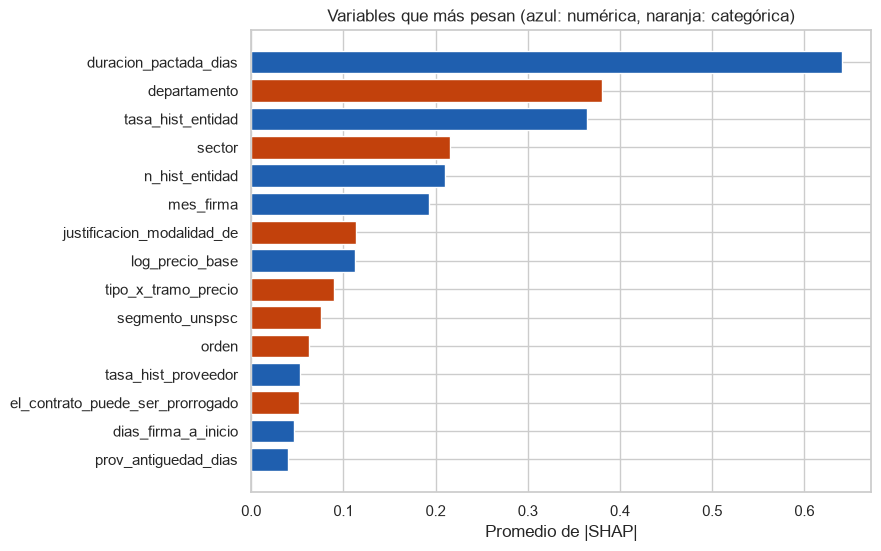

In [7]:
top = importancia.head(15).iloc[::-1]
colores = top["tipo"].map({"numérica": "#1F5FAF", "categórica": "#C2410C"})
plt.figure(figsize=(8, 6))
plt.barh(top.index, top["shap_medio_abs"], color=colores)
plt.xlabel("Promedio de |SHAP|")
plt.title("Variables que más pesan (azul: numérica, naranja: categórica)")
plt.show()

## 5. Dirección del efecto en variables **continuas**

Para una variable continua miramos si un valor **alto** sube o baja el riesgo. Cada punto es un contrato: en el eje X el valor de la variable, en el eje Y su SHAP (arriba de 0 sube el riesgo).

Cambia `variable` por otra de `NUMERICAS` para explorarla.

In [8]:
NUMERICAS

['log_precio_base',
 'duracion_pactada_dias',
 'supera_12_meses',
 'cruza_vigencia',
 'mes_firma',
 'dias_firma_a_inicio',
 'prov_antiguedad_dias',
 'proc_proveedores_invitados',
 'proc_respuestas_al_procedimiento',
 'proc_conteo_de_respuestas_a_ofertas',
 'proc_numero_de_lotes',
 'tiene_recursos_propios',
 'tiene_pgn',
 'tiene_sgp',
 'tiene_regalias',
 'tasa_hist_entidad',
 'n_hist_entidad',
 'tasa_hist_proveedor',
 'n_hist_proveedor']

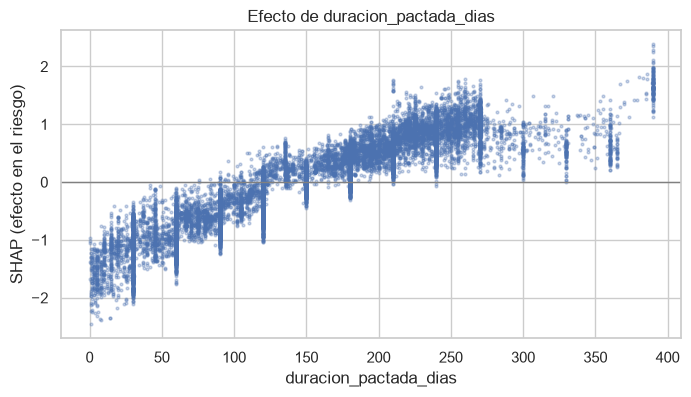

In [9]:
variable = "duracion_pactada_dias"

plt.figure(figsize=(8, 4))
plt.scatter(X[variable], shap_df[variable], s=4, alpha=0.3)
plt.axhline(0, color="gray", lw=1)
plt.xlabel(variable)
plt.ylabel("SHAP (efecto en el riesgo)")
plt.title(f"Efecto de {variable}")
plt.show()

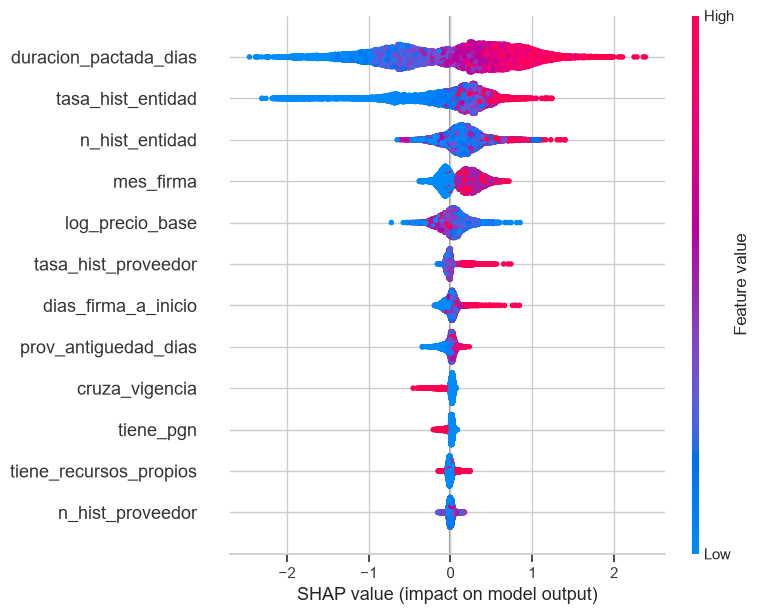

In [10]:
# Vista resumida de todas las numéricas (rojo = valor alto de la variable)
import shap
orden = [c for c in importancia.index if c in NUMERICAS][:12]
shap.summary_plot(shap_df[orden].to_numpy(), X[orden].astype(float), feature_names=orden, max_display=12)

## 6. Dirección del efecto en variables **categóricas**

Una categórica no tiene valores "altos" o "bajos", así que promediamos el SHAP de **cada categoría**: positivo sube el riesgo, negativo lo baja. Se muestran solo las categorías con al menos 100 contratos en la muestra.

Cambia `variable` por otra de `CATEGORICAS`.

In [11]:
CATEGORICAS

['tipo_de_contrato',
 'modalidad_de_contratacion',
 'justificacion_modalidad_de',
 'sector',
 'orden',
 'rama',
 'entidad_centralizada',
 'departamento',
 'destino_gasto',
 'origen_de_los_recursos',
 'el_contrato_puede_ser_prorrogado',
 'es_pyme',
 'es_grupo',
 'habilita_pago_adelantado',
 'obligaci_n_ambiental',
 'reversion',
 'espostconflicto',
 'tipodocproveedor',
 'segmento_unspsc',
 'tramo_precio',
 'tipo_x_tramo_precio']

In [12]:
def efecto_por_categoria(variable, min_n=100):
    return (pd.DataFrame({"categoria": X[variable], "shap": shap_df[variable]})
              .groupby("categoria")["shap"].agg(contratos="size", shap_medio="mean")
              .query("contratos >= @min_n")
              .sort_values("shap_medio", ascending=False))

efecto_por_categoria("departamento")

,contratos,shap_medio
categoria,,
Putumayo,161,0.522
La Guajira,180,0.474
Distrito Capital de Bogotá,5756,0.423
Cundinamarca,972,0.266
Cauca,329,0.216
Bolívar,668,0.079
Quindío,307,0.044
Atlántico,581,0.026
Santander,832,0.024


In [13]:
efecto_por_categoria("sector")

,contratos,shap_medio
categoria,,
Servicio Público,5223,0.165
Salud y Protección Social,2692,0.164
Cultura,826,0.132
Minas y Energía,100,0.128
deportes,769,0.079
No aplica/No pertenece,3480,0.037
Educación Nacional,1232,-0.007
defensa,696,-0.069
Ambiente y Desarrollo Sostenible,856,-0.122


## 7. Un contrato en particular: ¿por qué el modelo le dio ese riesgo?

Tomamos el contrato con mayor probabilidad de la muestra y ordenamos sus SHAP. Esto es lo que el tablero muestra como "factores que más aumentan el riesgo".

Cambia `id_contrato` por el índice de otro contrato (por ejemplo, uno de `muestra.sample(1).index`).

In [14]:
id_contrato = muestra["prob"].idxmax()
c = muestra.loc[id_contrato]
print(f"{c['tipo_de_contrato']} · {c['departamento']} · {c['duracion_pactada_dias']:.0f} días · "
      f"probabilidad {c['prob']:.1%} · ¿se prorrogó? {'sí' if c[OBJETIVO] else 'no'}")

factores = (pd.DataFrame({"valor": X.loc[id_contrato], "shap": shap_df.loc[id_contrato]})
              .sort_values("shap", key=abs, ascending=False).head(10))
factores

Prestación de servicios · Magdalena · 210 días · probabilidad 91.5% · ¿se prorrogó? sí


,valor,shap
duracion_pactada_dias,210.000,1.765
n_hist_entidad,"7,010.000",0.915
sector,Salud y Protección Social,0.558
departamento,Magdalena,0.427
tasa_hist_entidad,0.113,0.294
justificacion_modalidad_de,Regla aplicable,0.241
tipo_x_tramo_precio,Prestación de servicios | >1.000M,0.238
tasa_hist_proveedor,0.137,0.208
n_hist_proveedor,6.000,0.090
orden,Territorial,0.085


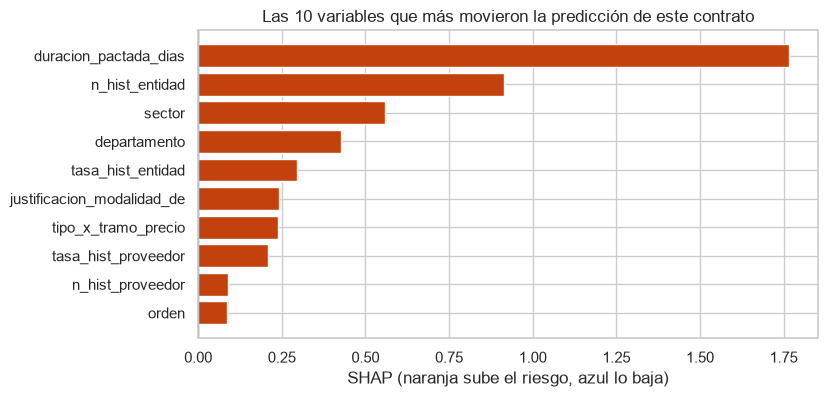

In [15]:
f = factores.iloc[::-1]
plt.figure(figsize=(8, 4))
plt.barh(f.index, f["shap"], color=np.where(f["shap"] > 0, "#C2410C", "#1F5FAF"))
plt.axvline(0, color="gray", lw=1)
plt.xlabel("SHAP (naranja sube el riesgo, azul lo baja)")
plt.title("Las 10 variables que más movieron la predicción de este contrato")
plt.show()

## 8. Para tener en cuenta

- SHAP describe **qué usa el modelo para predecir**, no qué **causa** la prórroga.
- Cada efecto se lee "manteniendo las demás variables": por ejemplo, el efecto del precio base es el que queda después de considerar la duración.
- Preguntas para seguir explorando: ¿el efecto del precio cambia según el tipo de contrato? ¿Qué departamentos suben el riesgo aunque su tasa histórica sea baja?